In [ ]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt

In [ ]:
#General rutine
def monte_carlo_integration(func, a, b, num_samples=1000):
    """
    Aproxima la integral definida de una función utilizando el método de Monte Carlo.

    Args:
        func: La función a integrar (debe ser una función de Python).
        a: El límite inferior de integración.
        b: El límite superior de integración.
        num_samples: El número de puntos aleatorios a generar.

    Returns:
        Una aproximación de la integral definida.
    """
    integral_sum = 0
    for _ in range(num_samples):
        # Generar un punto aleatorio en el intervalo [a, b]
        x = random.uniform(a, b)
        # Sumar el valor de la función en ese punto
        integral_sum += func(x)
    # Calcular el promedio y multiplicar por el ancho del intervalo
    integral_approx = (b - a) * (integral_sum / num_samples)
    return integral_approx

#1 $$\int_{0}^{4} x^{1/2} \, dx$$

In [ ]:
import scipy.integrate as integrate

def f(x):
  return x**0.5

integrate.quad(f,0,4)

(5.333333333333335, 5.921189464667503e-15)

In [ ]:
a = 0
b = 4
num_samples = 100000
# Compute the integral using MonteCarlo
integral_result = monte_carlo_integration(f, a, b, num_samples)

print(f"MonteCarlo value: {integral_result}")
print(f"Analytical result : {16/3}")
print('error', abs(integral_result-16/3))

MonteCarlo value: 5.345072138344595
Analytical result : 5.333333333333333
error 0.011738805011262343


Ahora resolveremos la siguiente integral mediante el mismo método.

$$ \int_{0}^{1} \int_{0}^{2} xy^{2} \, dx \, dy $$

In [ ]:
def monte_carlo_integration_2D(func, a, b, c, d, num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x = random.uniform(a, b)
        y = random.uniform(c, d)
        integral_sum += func(x, y)
    integral_approx = (b - a) * (d - c) * (integral_sum / num_samples)
    return integral_approx

In [ ]:
f2 = lambda y, x: x*y**2
print(integrate.dblquad(f2, 0, 2, 0, 1))


(0.6666666666666667, 7.401486830834377e-15)


In [ ]:
def f(x,y):
  return x*y**2

a=0
b=2
c=0
d=1

num_samples = 100000
integral_result2 = monte_carlo_integration_2D(f, a, b, c, d, num_samples)
print(f"MonteCarlo value: {integral_result2}")
print(f"Analytical result : {0.66667}")
print('error', abs(integral_result-0.66667))

MonteCarlo value: 0.6670236721276547
Analytical result : 0.66667
error 0.3391600930504096


#El resultado de la doble integral $$ \int_{0}^{1} \int_{0}^{2} xy \, dx \, dy $$ es aproximdamente 0.66667

#2 Modelo de Ising 2D


Ahora usando la siguiente formula, en donde consideramos la interacciones de las párticulas vecinas en la red cristalina con el fin de que el Hamiltoniano nos indique la energía del sistema:

 $$H = \sum_{<i,j>} -J\sigma_i\sigma_j$$

donde:

* $H$ es el hamiltoniano del sistema,
* $\displaystyle\sum_{<i,j>}$ denota una suma sobre partículas vecinas entre sí,
* $\sigma_i$ es el espín de la partícula $i$-ésima, que puede tomar sólo dos valores, $+1$ y $-1$, y
* $J$ es el factor de escala entre interacción entre espines y energía. Es un parámetro de la teoría.

En este caso hemos usado J=1/2

Energía total del sistema: 2.0


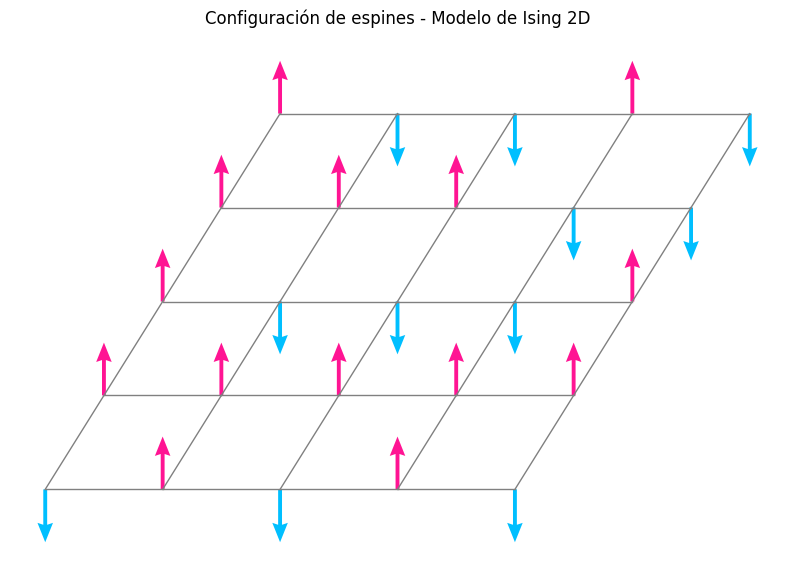

In [ ]:
def calcular_energia(espines, J=0.5):
    N = espines.shape[0]
    suma_interacciones = 0

    # 1. Interacciones horizontales (izquierda - derecha)
    for j in range(N):
        for i in range(N - 1):
            suma_interacciones += espines[j, i] * espines[j, i + 1]

    # 2. Interacciones verticales (arriba - abajo)
    for j in range(N - 1):
        for i in range(N):
            suma_interacciones += espines[j, i] * espines[j + 1, i]

    # Hamiltoniano: H = -J * sum(sigma_i * sigma_j)
    energia = -J * suma_interacciones
    return energia


def graficar_espines(espines):

    N = len(espines)

    # Coordenadas de los sitios de la red
    x = []
    y = []

    for j in range(N):
        for i in range(N):

            x.append(i + 0.5*j)
            y.append(j*0.8)

    x = np.array(x)
    y = np.array(y)

    # Convertir la matriz en un vector
    s = espines.flatten()

    # Dibujar la red cristalina
    plt.figure(figsize=(10, 7))

    # Conexiones horizontales
    for j in range(N):
        for i in range(N-1):

            x1 = i + 0.5*j
            x2 = i + 1 + 0.5*j
            yy = j*0.8

            plt.plot([x1, x2], [yy, yy],
                     color='gray', linewidth=1)

    # Conexiones diagonales
    for j in range(N-1):
        for i in range(N):

            x1 = i + 0.5*j
            x2 = i + 0.5*(j+1)

            y1 = j*0.8
            y2 = (j+1)*0.8

            plt.plot([x1, x2], [y1, y2],
                     color='gray', linewidth=1)

    # Colores de los espines
    colores = []

    for spin in s:

        if spin == 1:
            colores.append('deeppink')
        else:
            colores.append('deepskyblue')

    # Dibujar las flechas
    plt.quiver(
        x, y,
        np.zeros(len(s)),
        s*0.45,
        color=colores,
        angles='xy',
        scale_units='xy',
        scale=1,
        width=0.005,
        headwidth=4,
        headlength=5
    )

    plt.title("Configuración de espines - Modelo de Ising 2D")
    plt.axis('equal')
    plt.axis('off')
    plt.show()


# Ejemplo con matriz 5x5 aleatoria en cada ejecución
espines = np.random.choice([-1, 1], size=(5, 5))

E = calcular_energia(espines, J=0.5)
print(f"Energía total del sistema: {E}")

graficar_espines(espines)

Energía total del sistema: 4.0


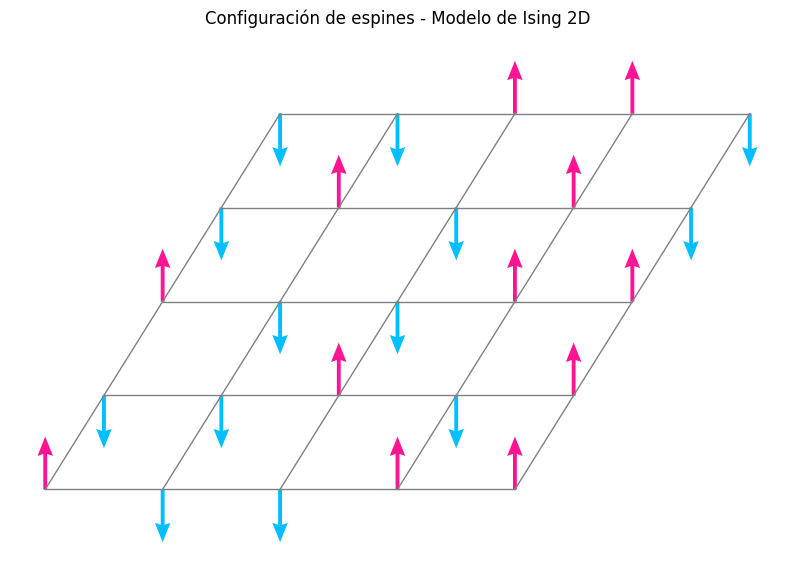

In [ ]:


def calcular_energia(espines, J=0.5):
    N = espines.shape[0]
    suma_interacciones = 0

    # 1. Interacciones horizontales (izquierda - derecha)
    for j in range(N):
        for i in range(N - 1):
            suma_interacciones += espines[j, i] * espines[j, i + 1]

    # 2. Interacciones verticales (arriba - abajo)
    for j in range(N - 1):
        for i in range(N):
            suma_interacciones += espines[j, i] * espines[j + 1, i]

    # Hamiltoniano: H = -J * sum(sigma_i * sigma_j)
    energia = -J * suma_interacciones
    return energia


def graficar_espines(espines):

    N = len(espines)

    # Coordenadas de los sitios de la red
    x = []
    y = []

    for j in range(N):
        for i in range(N):

            x.append(i + 0.5*j)
            y.append(j*0.8)

    x = np.array(x)
    y = np.array(y)

    # Convertir la matriz en un vector
    s = espines.flatten()

    # Dibujar la red cristalina
    plt.figure(figsize=(10, 7))

    # Conexiones horizontales
    for j in range(N):
        for i in range(N-1):

            x1 = i + 0.5*j
            x2 = i + 1 + 0.5*j
            yy = j*0.8

            plt.plot([x1, x2], [yy, yy],
                     color='gray', linewidth=1)

    # Conexiones diagonales
    for j in range(N-1):
        for i in range(N):

            x1 = i + 0.5*j
            x2 = i + 0.5*(j+1)

            y1 = j*0.8
            y2 = (j+1)*0.8

            plt.plot([x1, x2], [y1, y2],
                     color='gray', linewidth=1)

    # Colores de los espines
    colores = []

    for spin in s:

        if spin == 1:
            colores.append('deeppink')
        else:
            colores.append('deepskyblue')

    # Dibujar las flechas
    plt.quiver(
        x, y,
        np.zeros(len(s)),
        s*0.45,
        color=colores,
        angles='xy',
        scale_units='xy',
        scale=1,
        width=0.005,
        headwidth=4,
        headlength=5
    )

    plt.title("Configuración de espines - Modelo de Ising 2D")
    plt.axis('equal')
    plt.axis('off')
    plt.show()


# Ejemplo con matriz 5x5 aleatoria en cada ejecución
espines = np.random.choice([-1, 1], size=(5, 5))

E = calcular_energia(espines, J=0.5)
print(f"Energía total del sistema: {E}")

graficar_espines(espines)

El código se corrió 2 veces para mostrar que el valor del hamiltoniano si cambia dependiendo de cómo se genera la red de spin. En el primer ensayo dio 2.0 con su configuración especifica de Ising 2D. Mientras que en el segundo ensayo dio un valor de 4.0.

#PRUEBAAA



## Ahora el cálculo para el campo magnético variable

Las constantes $\mu_B$ y $k_B$ son el magnetón de Bohr y la constante de Boltzmann respectivamente, y tienen un valor de:

* $\mu_B = 9.2740100783 \times 10^{-24} \text{ J/T}$
* $k_B = 1.380649 \times 10^{-23} \text{ J/K}$



In [113]:
def metropolis_mc(L, T, H, muB=9.2740100783e-24, kb=1.380649e-23, steps=100_000):
    """
    Simulación de Monte Carlo para un sistema 2D de espines no interactuantes.
    L: Tamaño de la red (sL x L)
    T: Temperatura
    H: Campo magnético
    """
    # 1. Configuración inicial aleatoria (+1 o -1)
    grid = np.random.choice([-1, 1], size=(L, L))
    N = L * L

    # Para estabilizar el sistema (termalización), descartamos los primeros pasos
    termalization_steps = int(0.1 * steps)

    magnetization_sum = 0
    samples = 0

    for step in range(steps):
        # 2. Visitar aleatoriamente un punto de la red
        i, j = np.random.randint(0, L, size=2)
        spin = grid[i, j]

        # 3. Comprobar energía (solo importa el término del campo externo al no haber interacción)
        dE = 2.0 * muB * H * spin
        # Aceptación de Metrópolis
        if dE < 0:
            grid[i, j] = -spin
        else:
            r = np.random.rand()
            if r < np.exp(-dE / (kb * T)):
                grid[i, j] = -spin

        # Tomar medidas después de la termalización para evitar el sesgo inicial
        if step > termalization_steps:
            magnetization_sum += np.sum(grid)
            samples += 1

    # Retorna la magnetización media por átomo y por unidad de tiempo
    return magnetization_sum / (samples * N)

Lo compararemos con la solución analítica que se encuentra en el Notebook y que tiene la siguiente forma:

$$\langle M \rangle = N \mu_B \tanh\left(\frac{\mu_B H}{k_B T}\right)$$


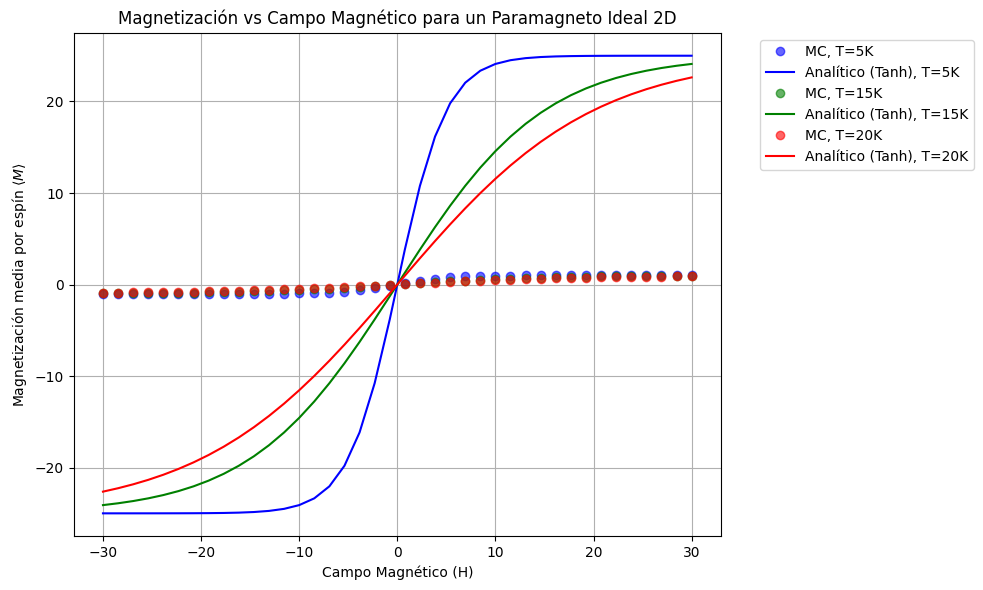

In [114]:

muB = 9.2740100783e-24
kb = 1.380649e-23
L = 5  # Red de 5x5 = 25 átomos
N = 25
T_values = [5, 15, 20]
H_values = np.linspace(-30, 30, 40)

# Diccionarios para almacenar resultados
M_mc = {T: [] for T in T_values}
M_analytical = {T: [] for T in T_values}
M_classical = {T: [] for T in T_values}

for T in T_values:
    for H in H_values:
        # Resultado de Monte Carlo
        M_mc[T].append(metropolis_mc(L, T, H, muB=muB, kb=kb, steps=50000))

        # 3. Resultado Analítico Exacto (Mecánica Estadística Cuántica, spin 1/2)
        M_analytical[T].append(N * muB * np.tanh((muB * H) / (kb * T)))

# Graficar
plt.figure(figsize=(10, 6))

colors = {5: 'blue', 15: 'green', 20: 'red'}

for T in T_values:
    plt.plot(H_values, M_mc[T], 'o', color=colors[T], label=f'MC, T={T}K', alpha=0.6)
    plt.plot(H_values, M_analytical[T], '-', color=colors[T], label=f'Analítico (Tanh), T={T}K')

plt.xlabel('Campo Magnético (H)')
plt.ylabel('Magnetización media por espín $\\langle M \\rangle$')
plt.title('Magnetización vs Campo Magnético para un Paramagneto Ideal 2D')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Aquí observamos que la solución Monte-Carlo es casi una linea recta, pero esto se debe a la diferencia en los ordenes de magnitud. Si usamos unidades naturales tales que:
* $\mu_B = 1$
* $k_B = 1$

Definimos entonces un nuevo Metropolis Monte carlo con los valores iguales a 1.

In [116]:
def metropolis_mc2(L, T, H, muB=1, kb=1, steps=100_000):
    """
    Simulación de Monte Carlo para un sistema 2D de espines no interactuantes.
    L: Tamaño de la red (sL x L)
    T: Temperatura
    H: Campo magnético
    """
    # 1. Configuración inicial aleatoria (+1 o -1)
    grid = np.random.choice([-1, 1], size=(L, L))
    N = L * L

    # Para estabilizar el sistema (termalización), descartamos los primeros pasos
    termalization_steps = int(0.1 * steps)

    magnetization_sum = 0
    samples = 0

    for step in range(steps):
        # 2. Visitar aleatoriamente un punto de la red
        i, j = np.random.randint(0, L, size=2)
        spin = grid[i, j]

        # 3. Comprobar energía (solo importa el término del campo externo al no haber interacción)
        dE = 2.0 * muB * H * spin
        # Aceptación de Metrópolis
        if dE < 0:
            grid[i, j] = -spin
        else:
            r = np.random.rand()
            if r < np.exp(-dE / (kb * T)):
                grid[i, j] = -spin

        # Tomar medidas después de la termalización para evitar el sesgo inicial
        if step > termalization_steps:
            magnetization_sum += np.sum(grid)
            samples += 1

    # Retorna la magnetización media por átomo y por unidad de tiempo
    return magnetization_sum / (samples * N)

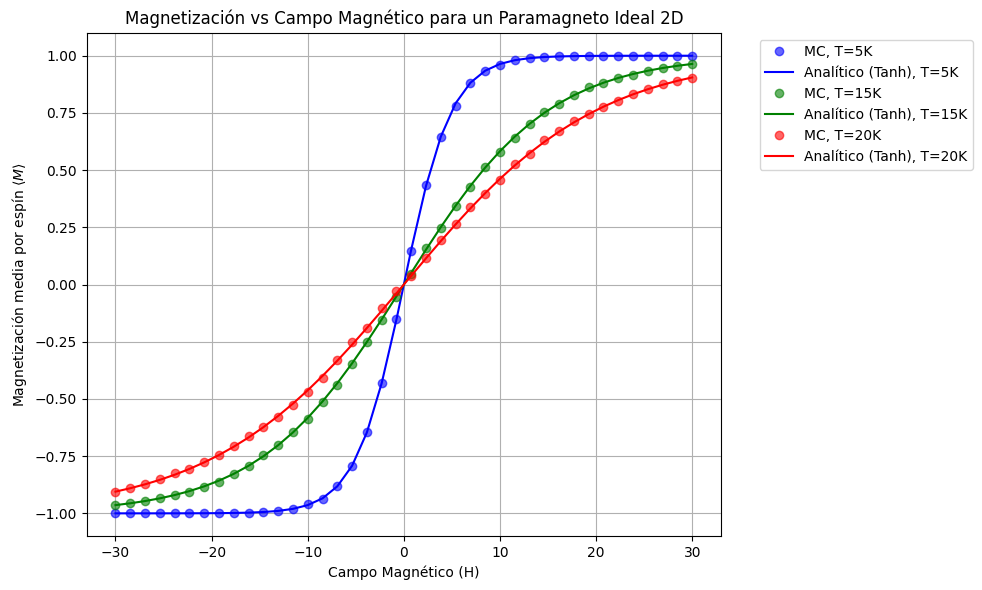

In [118]:
muB2 = 1
kb2 = 1
L = 5  # Red de 5x5 = 25 átomos
N = 25
T_values = [5, 15, 20]
H_values = np.linspace(-30, 30, 40)

# Diccionarios para almacenar resultados
M_mc = {T: [] for T in T_values}
M_analytical = {T: [] for T in T_values}
M_classical = {T: [] for T in T_values}

for T in T_values:
    for H in H_values:
        # Resultado de Monte Carlo
        M_mc[T].append(metropolis_mc2(L, T, H, muB=muB2, kb=kb2, steps=50000))

        # 3. Resultado Analítico Exacto (Mecánica Estadística Cuántica, spin 1/2)
        M_analytical[T].append(np.tanh((H)/(T)))

# Graficar
plt.figure(figsize=(10, 6))

colors = {5: 'blue', 15: 'green', 20: 'red'}

for T in T_values:
    plt.plot(H_values, M_mc[T], 'o', color=colors[T], label=f'MC, T={T}K', alpha=0.6)
    plt.plot(H_values, M_analytical[T], '-', color=colors[T], label=f'Analítico (Tanh), T={T}K')

plt.xlabel('Campo Magnético (H)')
plt.ylabel('Magnetización media por espín $\\langle M \\rangle$')
plt.title('Magnetización vs Campo Magnético para un Paramagneto Ideal 2D')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Se observa finalmente como la solución por Monte carlos y la analítica se comportan iguales.